# Sprint 4 — Iteração de atributos, retreino dos baselines e pipeline congelado
**Trilha B — Qualidade do ar inadequada para corrida e ciclismo em São Paulo**

O código está em `src/sprint4_features.py`. Este notebook executa o script e mostra as evidências de cada item do diário da Sprint 4.

| Regra da sprint | Como é cumprida |
|---|---|
| Mesmo split da Sprint 2 | corte em 14/04/2026 00:00; mesma purga de 24 h da Sprint 3 (13.992 linhas de treino, 3.480 de teste) |
| Features novas motivadas pelos erros da Sprint 3 | erros analisados numa **validação interna** (jan–abr/2026, dentro do treino), não no teste |
| Seleção só no treino | 3 janelas de validação temporal dentro do treino; o teste não participa |
| Sem vazamento | teste automático: recalcular as features apagando o futuro não muda o valor em `t` |
| Pipeline congelado | `ColumnTransformer` salvo em `models/` e lista de colunas em `config/params.yaml` |
| Retreino + lift | Dummy, persistência e Naive Bayes retreinados no mesmo split; teste medido **uma vez** |

Execute com a pasta `Projeto-TrilhaB` aberta e o kernel `.venv`.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

raiz = Path.cwd().resolve()
if raiz.name == "notebooks":
    raiz = raiz.parent
sys.path.insert(0, str(raiz / "src"))
import sprint4_features as s4

resultado = s4.main()


=== SPRINT 4 — features novas, pipeline congelado e lift ===
Treino utilizado: 13992 | teste: 3480 | features: 25 (yeo_johnson)
Validacao interna (media de 3 janelas):
  S2 (39 features, standard): recall 0.463 | F1 0.403
  S4 (25 features, yeo_johnson): recall 0.786 | F1 0.619

Lift no teste (classe 1):
                       recall_classe_1_s3  recall_classe_1_s4  f1_classe_1_s3  f1_classe_1_s4  delta_recall  delta_f1  fn_s3  fn_s4  delta_fn  fp_s3  fp_s4
modelo                                                                                                                                                     
DummyClassifier                    0.0000              0.0000          0.0000          0.0000        0.0000    0.0000    299    299         0      0      0
Persistencia temporal              0.4849              0.4849          0.4825          0.4825        0.0000    0.0000    154    154         0    157    157
Gaussian Naive Bayes               0.3980              0.6254        

## 1. Erros da Sprint 3 que motivam as features

Para não usar o teste na escolha de features, os baselines da Sprint 3 foram retreinados com dados até 31/12/2025 e avaliados de **01/01/2026 até o corte** — período que pertence ao treino.

Recall por tipo de hora positiva (validação interna):


,tipo_positivo,positivos,recall_nb_s3,recall_persistencia
0,continuacao,232,0.7672,1.0
1,inicio_de_episodio,98,0.2959,0.0


Mediana das variáveis nas horas positivas — acertos (TP) vs falsos negativos (FN) do Naive Bayes S3:


,grupo,ozone,ozone_media_8h,ozone_lag_24h,temperature_2m,hora
0,FN,81.0,127.0,66.0,22.2,19.0
1,TP,151.0,154.8,141.0,26.4,16.0


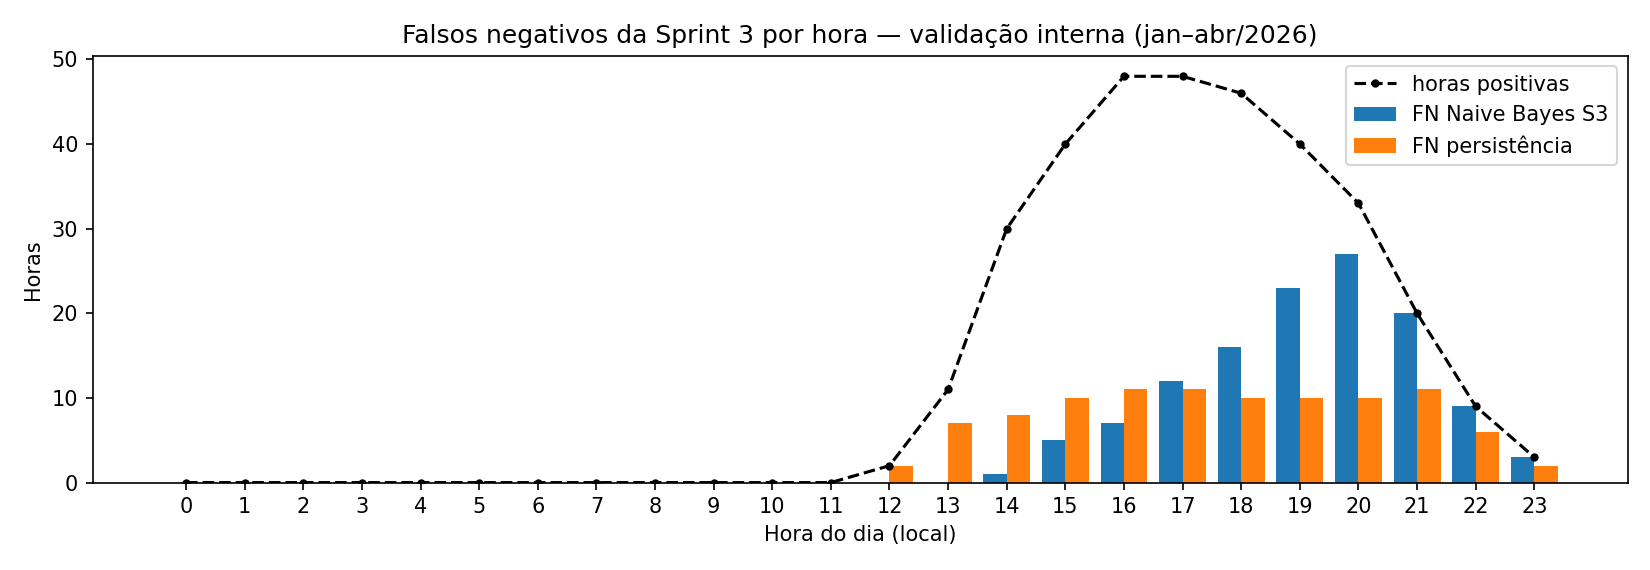

In [2]:
rep = raiz / "reports/sprint4"
print("Recall por tipo de hora positiva (validação interna):")
display(pd.read_csv(rep / "erros_s3_validacao_por_tipo.csv"))
print("Mediana das variáveis nas horas positivas — acertos (TP) vs falsos negativos (FN) do Naive Bayes S3:")
display(pd.read_csv(rep / "erros_s3_validacao_tp_vs_fn.csv"))
display(Image(filename=str(rep / "erros_s3_validacao_por_hora.png")))

**Leitura dos erros (o que as features precisam atacar):**

1. **FN do Naive Bayes no fim da tarde e à noite.** Os FN se concentram entre 17 h e 22 h. Nas horas perdidas, o ozônio *instantâneo* já caiu (mediana 81 µg/m³), mas a **média de 8 h** — que é a métrica da CETESB e define o alvo — ainda está perto do limite (127 µg/m³). As features da Sprint 2 só tinham o valor da hora e a média de 24 h, nenhuma na janela de 8 h.
2. **Início de episódio.** Quase 30 % das horas positivas começam um episódio (`estado_atual = 0` hoje, `1` amanhã). A persistência erra todas por definição, e o NB acerta só 30 %. É preciso informação sobre **o dia que está esquentando**, e não só sobre a hora atual.
3. **Hora como número.** `hora = 23` e `hora = 0` ficam distantes numa escala linear, e o NB gaussiano supõe uma curva em sino por classe. Isso não representa um ciclo de 24 h com pico às 17 h.
4. **Redundância.** PM10 e PM2,5 têm correlação de 0,97 no treino, e cada variável aparece 4 vezes (valor, lag 1 h, lag 24 h, média 24 h). O NB trata tudo como evidência independente e "conta duas vezes".

## 2. Features novas

| Feature | Definição (só `t` e passado) | Erro que ataca |
|---|---|---|
| `ozone_media_8h` | média do O₃ nas 8 h terminando em `t` | (1) é a métrica CETESB do alvo; mostra que o episódio ainda está acima do limite mesmo com O₃ instantâneo baixo |
| `ozone_max_8h` | máximo do O₃ nas últimas 8 h | (1) guarda o pico da tarde depois que o sol se põe |
| `ozone_8h_max_24h` | maior média de 8 h nas últimas 24 h (índice diário) | (2) quão forte foi o dia |
| `ozone_8h_max_24h_delta` | índice diário de hoje − de ontem | (2) episódio em formação (dias piorando) |
| `horas_ruins_24h` | nº de horas em classe N3+ nas últimas 24 h | (2) duração do episódio atual |
| `temperature_max_24h` | máxima de temperatura nas últimas 24 h | (2) calor acelera a formação de O₃ |
| `temperature_max_24h_delta` | máxima de hoje − de ontem | (2) frente quente chegando |
| `hora_sin`, `hora_cos` | hora codificada no círculo de 24 h | (3) 23 h fica vizinha de 0 h; o ciclo vira contínuo |
| `mes_sin`, `mes_cos` | mês codificado no círculo de 12 meses | (3) dezembro vizinho de janeiro |
| `elevacao_solar_alvo` | altura do sol (graus) em São Paulo na hora **prevista** `t + 24 h`, pela fórmula astronômica da NOAA | (1)(2) o O₃ é fotoquímico; a posição do sol é conhecida com antecedência, então não há vazamento |

Nenhuma delas é uma feature da Sprint 2 renomeada: as janelas (8 h, máximo diário, deltas de 24 h), a contagem de episódio, a codificação cíclica e a geometria solar não existiam.

In [3]:
print("Teste de vazamento — instantes verificados (features idênticas com e sem o futuro):")
for t in resultado["teste_vazamento_instantes"]:
    print("  ", t)
novas = pd.read_csv(raiz / "data/processed/treino_features_s4.csv", parse_dates=["timestamp"])
display(novas[s4.NEW_FEATURES].describe().T.round(2))

Teste de vazamento — instantes verificados (features idênticas com e sem o futuro):
   2024-09-10 04:00:00
   2025-02-02 06:00:00
   2025-06-27 09:00:00
   2025-11-19 12:00:00
   2026-04-13 15:00:00
   2026-09-05 18:00:00


,count,mean,std,min,25%,50%,75%,max
ozone_media_8h,14016.0,77.73,43.40,0.00,45.12,68.62,104.28,309.50
ozone_max_8h,14016.0,112.01,54.20,0.00,68.00,108.00,150.00,343.00
ozone_8h_max_24h,14010.0,132.84,39.56,47.12,103.62,131.38,157.25,309.50
ozone_8h_max_24h_delta,13986.0,-0.05,33.79,-137.50,-20.00,1.12,20.75,119.38
horas_ruins_24h,13994.0,3.35,4.15,0.00,0.00,1.00,6.00,24.00
temperature_max_24h,14016.0,26.38,4.18,12.80,23.60,26.45,29.40,36.20
temperature_max_24h_delta,13993.0,-0.00,3.12,-17.00,-1.50,0.40,1.90,9.50
hora_sin,14016.0,-0.00,0.71,-1.00,-0.71,0.00,0.71,1.00
hora_cos,14016.0,-0.00,0.71,-1.00,-0.71,-0.00,0.71,1.00
mes_sin,14016.0,-0.07,0.72,-1.00,-0.87,0.00,0.50,1.00


## 3. Seleção de atributos e da normalização (só no treino)

**Validação temporal dentro do treino:** três janelas consecutivas (jul–set/2025, out–dez/2025, jan–abr/2026). Em cada uma, o Naive Bayes é treinado **só com o passado**, com purga de 24 h antes da janela. A métrica é o **F1 médio da classe 1** (recall como desempate): sem ajuste de limiar (Sprint 5), o F1 impede escolher um conjunto que "acerta" só porque marca tudo como ruim.

**Procedimento:** começando com as 39 features da Sprint 2 + as 12 novas, remove-se a **família** (por exemplo, o ozônio com seus 4 derivados) cuja retirada mais aumenta o F1 médio, até nenhuma remoção melhorar. Isso foi feito para as duas normalizações candidatas.

In [4]:
selecao = pd.read_csv(rep / "selecao_validacao.csv")
display(selecao.round(4))

ref = resultado["validacao_s2_por_normalizacao"]
sel = resultado["selecao_por_normalizacao"]
decomp = pd.DataFrame({
    "configuração": ["S2 (39) + StandardScaler  ← Sprint 3", "S2 (39) + Yeo-Johnson",
                     f"S4 ({sel['standard']['n_features']}) + StandardScaler",
                     f"S4 ({sel['yeo_johnson']['n_features']}) + Yeo-Johnson  ← congelado"],
    "recall médio": [ref["standard"]["recall_medio"], ref["yeo_johnson"]["recall_medio"],
                     sel["standard"]["recall_medio"], sel["yeo_johnson"]["recall_medio"]],
    "F1 médio": [ref["standard"]["f1_medio"], ref["yeo_johnson"]["f1_medio"],
                 sel["standard"]["f1_medio"], sel["yeo_johnson"]["f1_medio"]],
}).round(3)
print("Decomposição do ganho na VALIDAÇÃO (não é o teste):")
display(decomp)
print("Normalização escolhida:", resultado["normalizacao_escolhida"])
print("Features congeladas:", resultado["n_features"])
print(resultado["features_congeladas"])

,normalizacao,passo,removida,n_features,recall_medio,f1_medio,f1_por_janela
0,standard,0,(todas as features S2 + novas),51,0.6285,0.5147,"[0.3789, 0.5512, 0.6141]"
1,standard,1,temperature_2m,47,0.6236,0.5273,"[0.3904, 0.5737, 0.6179]"
2,standard,2,ozone,43,0.5981,0.5461,"[0.3581, 0.6073, 0.6729]"
3,standard,3,pm10,39,0.7048,0.5710,"[0.4401, 0.6208, 0.6523]"
4,standard,4,temp_max,37,0.7328,0.5883,"[0.4688, 0.6391, 0.6569]"
5,standard,5,carbon_monoxide,33,0.7513,0.5942,"[0.4924, 0.6403, 0.6499]"
6,standard,6,precipitation,29,0.7435,0.5999,"[0.4855, 0.636, 0.6781]"
7,standard,7,sulphur_dioxide,25,0.7311,0.6065,"[0.5057, 0.6347, 0.6792]"
8,standard,8,mes_ciclico,23,0.7335,0.6086,"[0.5018, 0.6366, 0.6874]"
9,standard,9,pico_diario,21,0.7641,0.6124,"[0.5149, 0.6429, 0.6794]"


Decomposição do ganho na VALIDAÇÃO (não é o teste):


,configuração,recall médio,F1 médio
0,S2 (39) + StandardScaler ← Sprint 3,0.463,0.403
1,S2 (39) + Yeo-Johnson,0.644,0.458
2,S4 (21) + StandardScaler,0.764,0.612
3,S4 (25) + Yeo-Johnson ← congelado,0.786,0.619


Normalização escolhida: yeo_johnson
Features congeladas: 25
['pm10', 'pm10_lag_1h', 'pm10_lag_24h', 'pm10_media_24h', 'sulphur_dioxide', 'sulphur_dioxide_lag_1h', 'sulphur_dioxide_lag_24h', 'sulphur_dioxide_media_24h', 'precipitation', 'precipitation_lag_1h', 'precipitation_lag_24h', 'precipitation_media_24h', 'wind_speed_10m', 'wind_speed_10m_lag_1h', 'wind_speed_10m_lag_24h', 'wind_speed_10m_media_24h', 'ozone_media_8h', 'ozone_max_8h', 'temperature_max_24h', 'temperature_max_24h_delta', 'hora_sin', 'hora_cos', 'mes_sin', 'mes_cos', 'elevacao_solar_alvo']


**Leitura:** só trocar a normalização já ajuda (F1 de 0,40 para 0,46), porque o NB gaussiano supõe distribuições em sino e as concentrações são muito assimétricas. As features novas e a remoção de redundância levam o F1 a 0,62.

**Mantidas (25):** famílias de PM10, SO₂, precipitação e vento; `ozone_media_8h`, `ozone_max_8h`; `temperature_max_24h` e delta; hora e mês cíclicos; elevação solar.
**Descartadas pela validação, com a hipótese do porquê:**
- **família do O₃ bruto** (valor, lags, média 24 h): substituída pela janela de 8 h, que carrega a mesma informação na escala do alvo;
- **temperatura bruta**: redundante com a máxima de 24 h e com a elevação solar;
- **PM2,5, NO₂ e CO**: muito correlacionados com o PM10 (tráfego/combustão); mantê-los faz o NB contar a mesma evidência várias vezes;
- **calendário bruto** (`hora`, `dia_semana`, `mes`): substituído pela versão cíclica. `dia_semana` não ajudou porque o alvo é dominado pelo O₃, que depende de sol, e não do tráfego de dias úteis;
- **pico diário e `horas_ruins_24h`**: a informação já está em `ozone_media_8h`/`ozone_max_8h` (com Yeo-Johnson, retirá-los melhorou a validação).

## 4. Pipeline de preparação congelado

| Etapa | Estratégia | Justificativa |
|---|---|---|
| Imputação | `SimpleImputer(strategy="median")`, ajustado no treino | só as primeiras ~48 h do histórico têm NaN por construção (janelas e deltas de 24 h); mediana é robusta às caudas longas dos poluentes |
| Encoding | hora e mês em seno/cosseno; nenhuma variável categórica | preserva o ciclo (23 h ↔ 0 h, dez ↔ jan) com 2 colunas numéricas, sem one-hot de 24 níveis |
| Normalização | `PowerTransformer(method="yeo-johnson", standardize=True)` | aproxima cada feature de uma normal, que é a hipótese do `GaussianNB`; aceita zeros (chuva, vento); escolhida contra o `StandardScaler` na validação temporal |
| Classificador | no mesmo `Pipeline` que o `ColumnTransformer` | `fit` só no treino; o teste passa apenas por `predict` |

O transformer **ajustado no treino** está em `models/column_transformer_s4.joblib`, o pipeline completo do NB em `models/naive_bayes_s4.joblib`, e a lista de colunas em `models/features_s4.json` e `config/params.yaml` (`sprint4.features_congeladas`). Se alguém reexecutar o script e a seleção mudar, ele **para com erro** em vez de trocar a lista em silêncio.

In [5]:
import joblib
transformer = joblib.load(raiz / "models/column_transformer_s4.joblib")
pipe_nb = joblib.load(raiz / "models/naive_bayes_s4.joblib")
display(pipe_nb)
print("Colunas congeladas no transformer:", list(transformer.transformers_[0][2]) == resultado["features_congeladas"])
normalizador = transformer.named_transformers_["numericas"]["normalizador"]
print("Normalizador ajustado no treino (lambdas de Yeo-Johnson por coluna):")
display(pd.Series(normalizador.lambdas_, index=resultado["features_congeladas"]).round(3).to_frame("lambda"))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('column_transformer', ...), ('classificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transform

Colunas congeladas no transformer: True
Normalizador ajustado no treino (lambdas de Yeo-Johnson por coluna):


,lambda
pm10,-0.076
pm10_lag_1h,-0.076
pm10_lag_24h,-0.074
pm10_media_24h,-0.130
sulphur_dioxide,-0.089
sulphur_dioxide_lag_1h,-0.089
sulphur_dioxide_lag_24h,-0.088
sulphur_dioxide_media_24h,0.116
precipitation,-7.987
precipitation_lag_1h,-7.987


## 5. Retreino dos três baselines e lift S3 → S4 (teste, medido uma vez)

,modelo,recall_classe_1_s3,recall_classe_1_s4,f1_classe_1_s3,f1_classe_1_s4,delta_recall,delta_f1,fn_s3,fn_s4,delta_fn,fp_s3,fp_s4
0,DummyClassifier,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,299,299,0,0,0
1,Persistencia temporal,0.4849,0.4849,0.4825,0.4825,0.0000,0.0000,154,154,0,157,157
2,Gaussian Naive Bayes,0.3980,0.6254,0.3324,0.4716,0.2274,0.1392,180,112,-68,298,307


,modelo,classe,precisao,recall,f1,suporte
0,DummyClassifier,0,0.9141,1.0000,0.9551,3181
1,DummyClassifier,1,0.0000,0.0000,0.0000,299
2,Persistencia temporal,0,0.9515,0.9506,0.9511,3181
3,Persistencia temporal,1,0.4801,0.4849,0.4825,299
4,Gaussian Naive Bayes,0,0.9625,0.9035,0.9321,3181
5,Gaussian Naive Bayes,1,0.3785,0.6254,0.4716,299


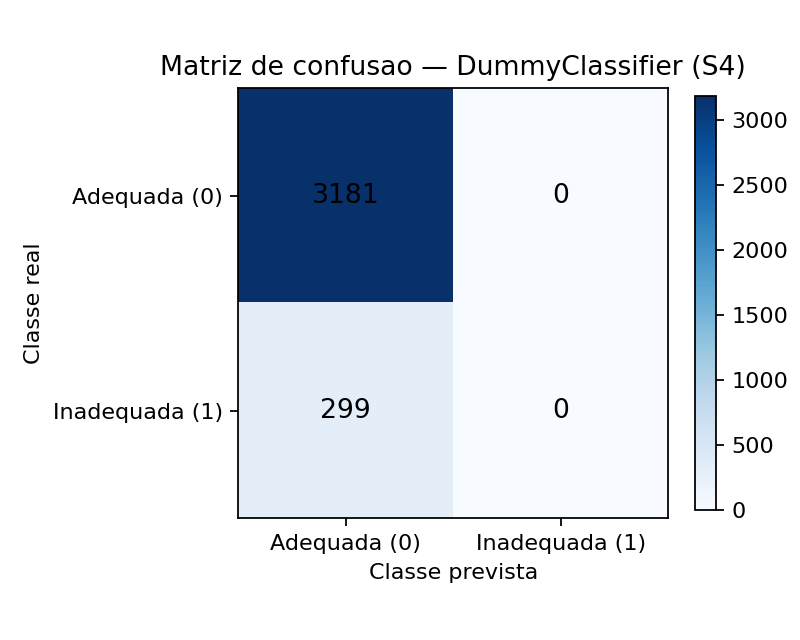

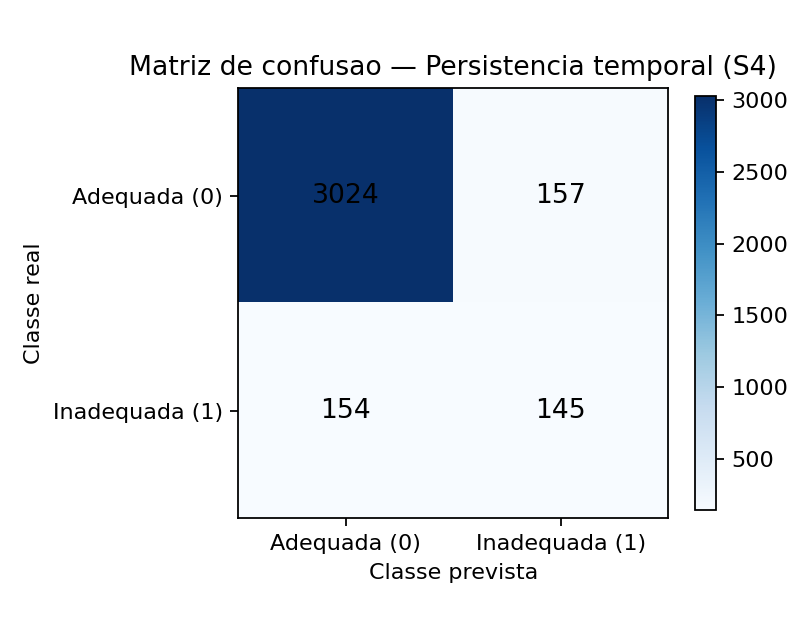

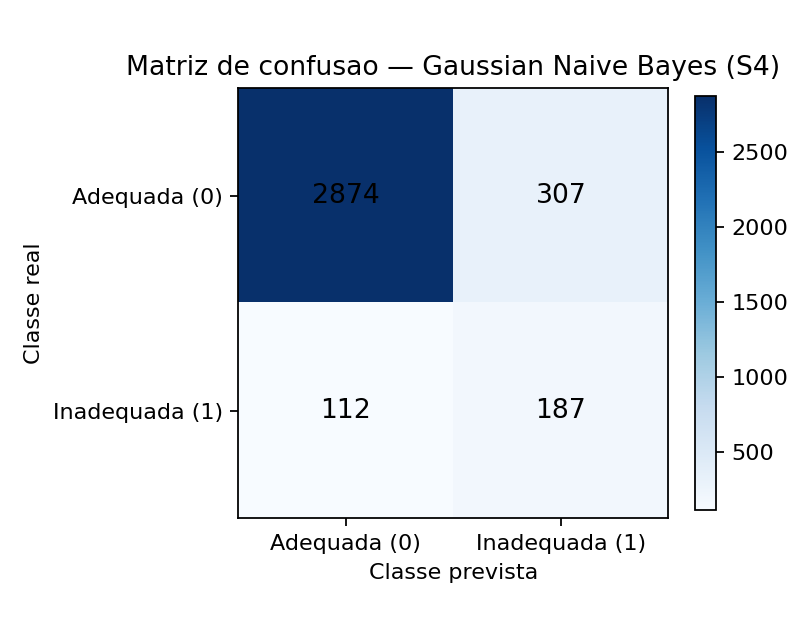

In [6]:
lift = pd.read_csv(rep / "lift_s3_s4.csv")
display(lift)
display(pd.read_csv(rep / "metricas_por_classe_s4.csv").round(4))
for stem in ("dummy", "persistencia", "naive_bayes"):
    display(Image(filename=str(rep / f"matriz_{stem}_s4.png")))

In [7]:
e3 = pd.read_csv(raiz / "reports/sprint3/erros_por_horario.csv", parse_dates=["timestamp"])
e4 = pd.read_csv(rep / "erros_por_horario_s4.csv", parse_dates=["timestamp"])
def fn_por_hora(e):
    f = e[(e["erro"] == "FN") & (e["modelo"] == "Gaussian Naive Bayes")]
    return f.groupby(f["timestamp"].dt.hour).size().reindex(range(24), fill_value=0)
h3, h4 = fn_por_hora(e3), fn_por_hora(e4)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(h3.index - 0.2, h3.values, width=0.4, label=f"NB Sprint 3 ({h3.sum()} FN)")
ax.bar(h4.index + 0.2, h4.values, width=0.4, label=f"NB Sprint 4 ({h4.sum()} FN)")
ax.set_xticks(range(24))
ax.set_xlabel("Hora do dia (local)")
ax.set_ylabel("Falsos negativos (horas)")
ax.set_title("Falsos negativos do Naive Bayes no teste por hora — antes e depois das features novas")
ax.legend()
plt.tight_layout()
plt.show()

C:\Users\nogut\AppData\Local\Temp\ipykernel_16852\3906419135.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 6. Interpretação do lift

- **Naive Bayes:** recall de **0,398 → 0,625** (+0,23) e F1 de **0,332 → 0,472** (+0,14). Os falsos negativos caíram de **180 para 112** (−68 horas), com praticamente o mesmo número de falsos positivos (298 → 307). A queda aconteceu exatamente onde a análise de erros apontava: no fim da tarde, os FN das 17 h–19 h passaram de 91 para 22.
- **Persistência:** sem mudança (recall 0,485, 154 FN). É uma regra que copia a classe de `t` para `t + 24 h`, então não usa features. Ela foi reexecutada no mesmo split e continua sendo o **piso** do comparativo da Sprint 5.
- **Dummy:** sem mudança (recall 0, 299 FN). Prevê sempre a classe majoritária, então as features não mudam nada. Continua mostrando que acurácia (91 %) não serve para este problema.
- **NB × persistência:** o NB agora detecta mais horas ruins (recall 0,625 contra 0,485; 112 FN contra 154), mas com mais alarmes falsos (307 contra 157 FP), e o F1 dos dois fica empatado (0,47 × 0,48). Escolher entre eles depende do limiar e do custo de FN, o que é tarefa da Sprint 5.
- **Limitação:** os ganhos na validação (F1 0,40 → 0,62) foram maiores que no teste (0,33 → 0,47). O teste (abr–set) tem menos episódios de ozônio que o treino, e a seleção gulosa pode ter se ajustado um pouco às janelas de validação. Por isso o teste foi usado uma única vez e não influenciou nenhuma escolha.